In [65]:
import os
import pandas as pd

import random
import numpy as np
import matplotlib.pyplot as plt
import librosa
import torch
import torchaudio

from IPython.display import Audio, display

In [66]:
N = 5                       
SPEC_TYPE = "mel"          
SAMPLE_RATE = 16000
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 128
TOP_DB = None 

if SPEC_TYPE == "linear":
    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        power=2.0
    )
elif SPEC_TYPE == "mel":
    spec_transform = torchaudio.transforms.MelSpectrogram(
        sample_rate=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )
else:
    raise ValueError("SPEC_TYPE must be 'linear' or 'mel'")


db_transform = torchaudio.transforms.AmplitudeToDB(
    stype="power",
    top_db=TOP_DB
)

def load_audio_track(path, trim=False, normalize=False, sr=16000, top_db=40):
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    # Resample if necessary
    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)

    # Normalize waveform
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak

    # Trim leading and trailing silence
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze()

def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        # x = np.concatenate([x, x[:num_samples]], axis=0)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        last_valid_start_sample = x_len - max_len
        if not last_valid_start_sample == 0:
            start_sample = random.randrange(start=0, stop=last_valid_start_sample)
        else:
            start_sample = 0
        x_pad = x[start_sample: start_sample + max_len]

    else:
        # TEST ON THE MIDDLE WINDOW
        num_windows = round(x_len / max_len)
        if num_windows % 2 == 1:  # odd no. of windows
            middle = num_windows//2
        else:  # even no. of windows
            middle = (num_windows//2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample: start_sample + max_len]

    return x_pad

def plot_spectrograms(generators=None, play_audio=False, sample_rate=16000):
    if generators is None:
        generators = sorted(df_all["generator"].unique())
        
    num_generators = len(generators)
    
    fig, axes = plt.subplots(
        num_generators,
        N,
        figsize=(4 * N, 3 * num_generators),
        squeeze=False
    )
    
    for row_idx, gen in enumerate(generators):
        df_gen = df_all[df_all["generator"] == gen]
        samples = df_gen.sample(min(N, len(df_gen)))
    
        for col_idx, (_, row) in enumerate(samples.iterrows()):
            path = row["path"]
    
            # ---- Load ----
            waveform = load_audio_track(path, trim=False, normalize=False)
            waveform = prepare_audio_window(torch.tensor(waveform))

            if play_audio:
                display(Audio(waveform.numpy(), rate=sample_rate))
    
            # ---- Spectrogram ----
            spec = spec_transform(waveform)
    
            # ---- Convert to dB ----
            spec_db = db_transform(spec)
            spec_db = spec_db.squeeze().numpy()
    
            ax = axes[row_idx, col_idx]
            im = ax.imshow(
                spec_db,
                aspect="auto",
                origin="lower",
                interpolation="nearest"
            )
            ax.set_title(f"{gen}")
            ax.set_xticks([])
            ax.set_yticks([])
    
    plt.tight_layout()
    plt.show()

In [48]:
ds = {
    "base_path": "/Database/ASVspoof2019/public_released_data",
    "train_file": "LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt",
    "dev_file": "LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt",
    "eval_file": "LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt",
    "train_dir": "LA/ASVspoof2019_LA_train/flac",
    "dev_dir": "LA/ASVspoof2019_LA_dev/flac",
    "eval_dir": "LA/ASVspoof2019_LA_eval/flac",
}

def process_split(df, split_dir):
    df = df.copy()
    
    df['label'] = df[4].map({'bonafide': 0, 'spoof': 1})
    df['path'] = df[1].apply(
        lambda x: os.path.join(ds['base_path'], split_dir, f"{x}.flac")
    )
    df['generator'] = df[3] 
    
    return df[['path', 'label', 'generator']]

In [60]:
df_train = pd.read_csv(os.path.join(ds['base_path'], ds['train_file']), sep=' ', header=None)
df_dev   = pd.read_csv(os.path.join(ds['base_path'], ds['dev_file']),   sep=' ', header=None)
df_test  = pd.read_csv(os.path.join(ds['base_path'], ds['eval_file']),  sep=' ', header=None)

df_train = process_split(df_train, ds['train_dir'])
df_dev   = process_split(df_dev,   ds['dev_dir'])
df_test  = process_split(df_test,  ds['eval_dir'])

df_all = pd.concat([df_train, df_dev, df_test], ignore_index=True)

/tmp/ipykernel_2882571/2540301258.py:112: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  waveform = prepare_audio_window(torch.tensor(waveform))


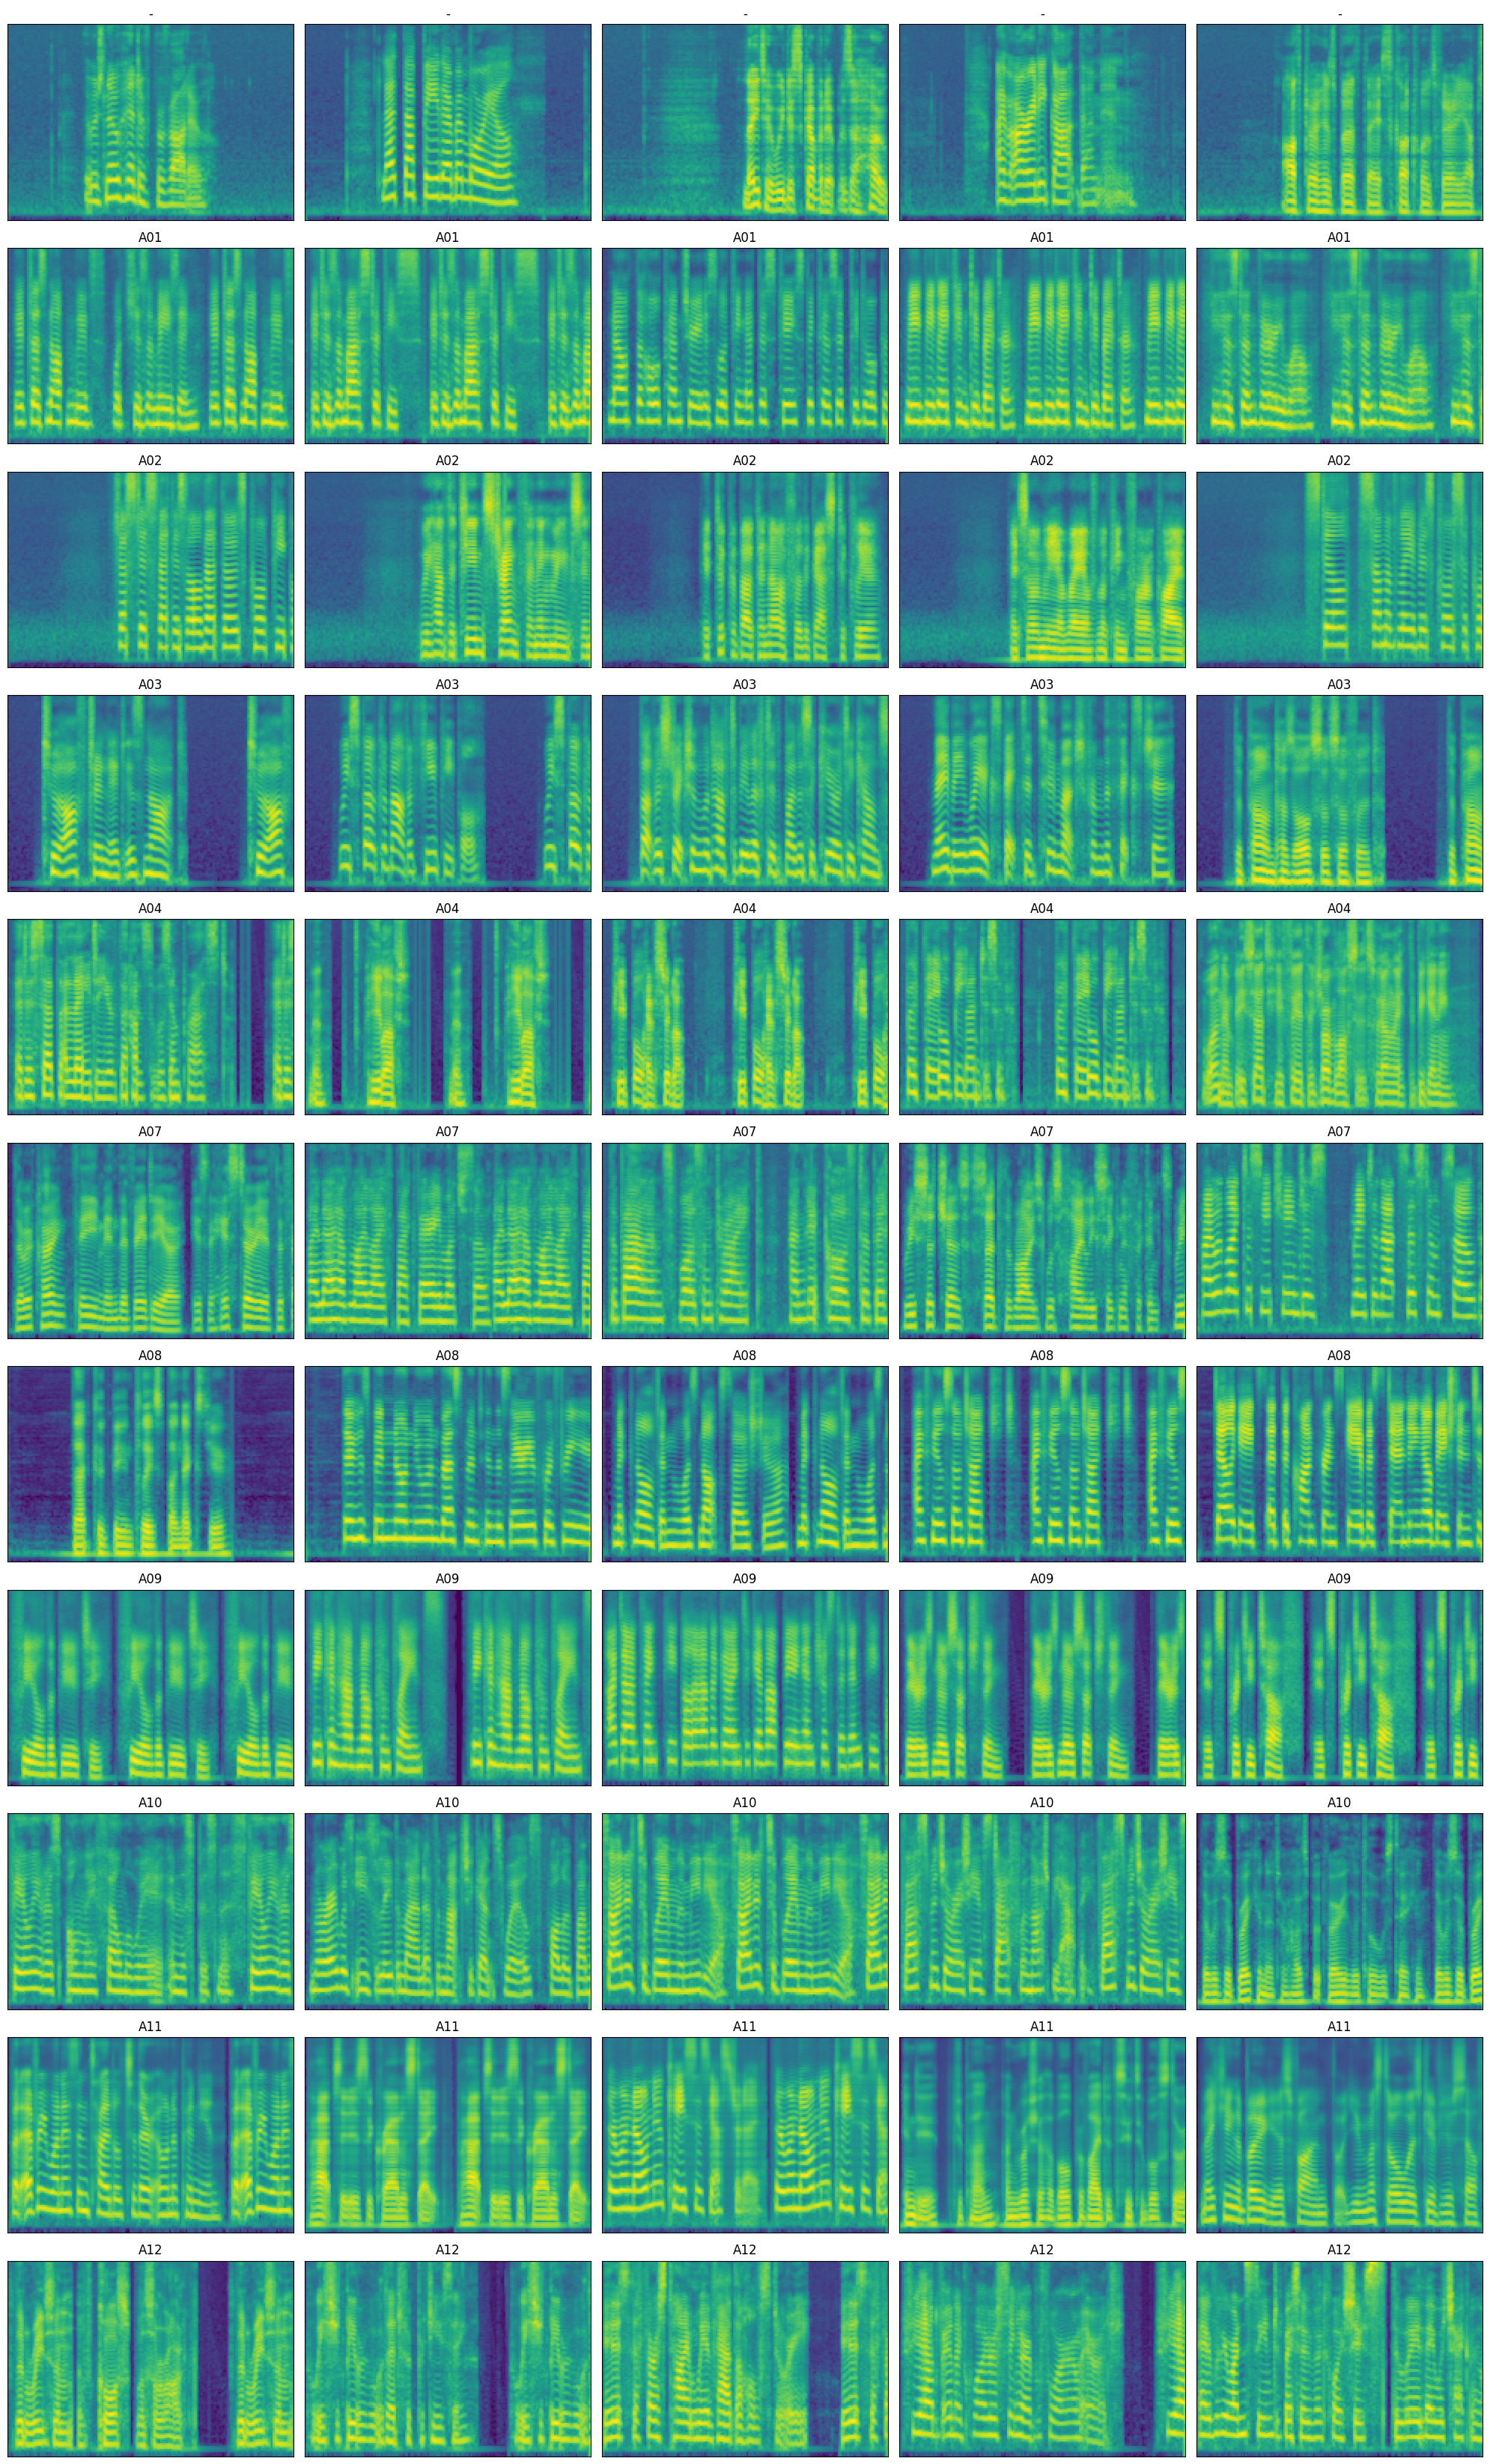

In [64]:
selected_generators = ['-', 'A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
plot_spectrograms(selected_generators)

/tmp/ipykernel_2882571/503953733.py:112: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  waveform = prepare_audio_window(torch.tensor(waveform))


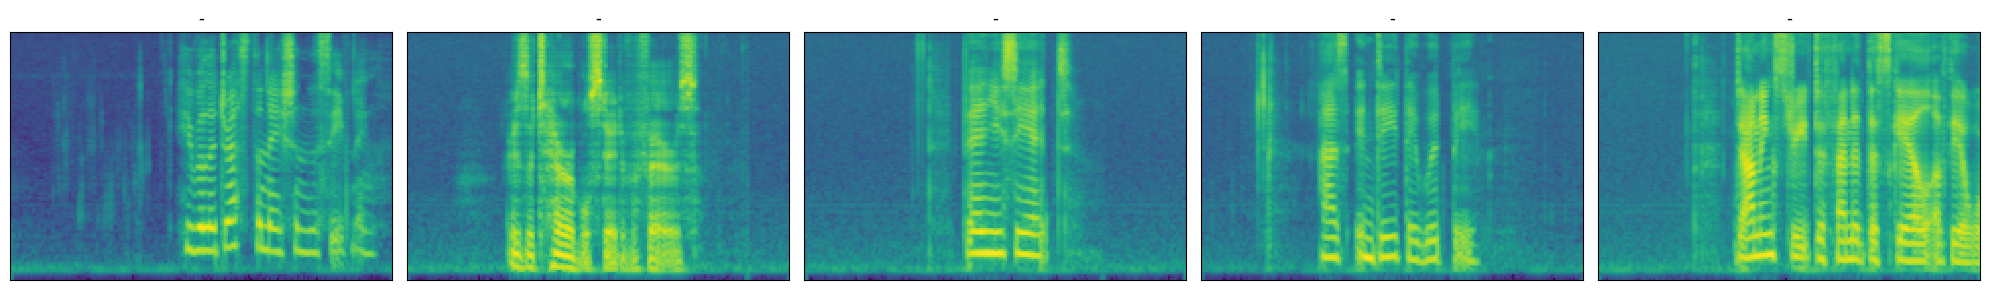

In [72]:
selected_generators = ['-']
plot_spectrograms(selected_generators, play_audio=True)

/tmp/ipykernel_2882571/503953733.py:112: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  waveform = prepare_audio_window(torch.tensor(waveform))


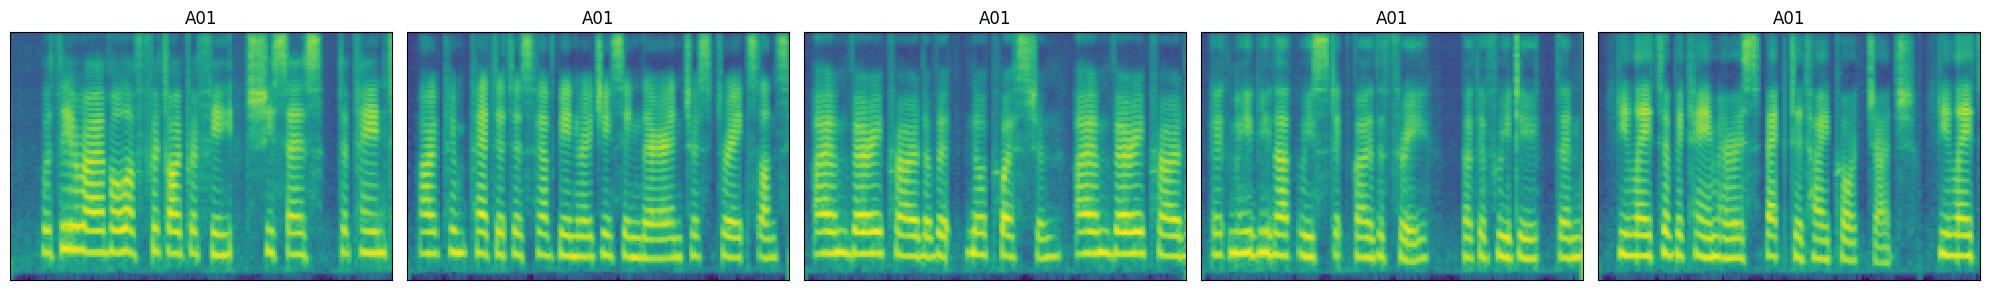

In [80]:
selected_generators = ['A01']
plot_spectrograms(selected_generators, play_audio=True)